# E3 — Retrieval & Interaction Machine (RIM)

Implementación propia en PyTorch de los componentes de RIM para regresión, basada en
[Qin et al., KDD2021](https://arxiv.org/abs/2108.05252) y el
[código de referencia](https://github.com/qinjr/RIM) en la revisión
`a6b4cdb347f306f9cf54a98fc994bf7112b53e9e`. El original usa TensorFlow1 y Elasticsearch.
Esta adaptación local no necesita esos servicios ni instala otra librería de modelos.

Código del estimador: `rim_regresion_e3.py`. Evaluación: `evaluar_rim_e3.py`.
Usar el venv compartido. Los notebooks históricos permanecen intactos.

## Arquitectura implementada

RIM trata la consulta como una fila y recupera filas relacionadas mediante BM25. Una atención
bilineal pondera sus embeddings y los de sus etiquetas. Se concatenan los quince campos de
la consulta, los quince agregados y el embedding agregado de etiqueta: 31 campos. Se calculan
sus 465 productos internos por pares y una MLP produce la nota, con conexión directa desde
la etiqueta agregada. La pérdida de regresión es MSE y la salida es lineal.

**Adaptaciones:** BM25 local con IDF positiva de Lucene; PyTorch; cuantiles para numéricos y
etiquetas recuperadas; MLP pequeña64/32 y LayerNorm en vez de la implementación histórica;
dropout0.1, objetivo estandarizado dentro de fit y Adam con weight_decay. La nota utilizada
como objetivo conserva sus decimales: solo se discretiza la representación de las notas de
vecinos. Se usa la conexión de etiquetas descrita en el artículo; el código de referencia no
la conecta en su rama de regresión. No es una reproducción exacta de sus benchmarks.

## Datos y prevención de fugas

Se reutiliza `entregable3.py`: datos reales sin aumentación, mismas reglas y outliers,
8 variables numéricas y7 categóricas, objetivo nota_primer_parcial. Se excluyen nota_final,
ID, periodo y fila fuente como predictores. Train1309 filas/1293 estudiantes y test202530
con188 filas/188 estudiantes. Se comprueban hashes y asignaciones guardadas del tablero.

Se clona la preparación del SVM dentro de cada fit: mediana, log1p para tiempos, escalado,
moda y vocabulario categórico. RIM requiere campos discretos: añade8 bins por cuantiles
numéricos y usa embeddings de categorías en lugar de introducir la matriz one-hot a la red.
Esto mantiene limpieza, variables e imputación comunes, con una representación específica
del modelo. Cortes y vocabularios se aprenden exclusivamente en fit, nunca en validación/test.

**Pool:** las filas del fit constituyen la memoria de recuperación. Para entrenar una consulta,
se excluyen todas las filas del mismo estudiante, no solo la fila. Los folds de validación y
el test nunca entran al pool, ni siquiera sus variables. Solo se usan las notas de vecinos
etiquetados de fit; la nota de la consulta no se introduce en la red ni en BM25.
Este uso leave-student-out del fit adapta las tres tablas separadas del artículo para no
reservar un tercer subconjunto pequeño. Si no hay coincidencias, la atención devuelve cero
para la memoria y se predice con la consulta. Padding y categorías nuevas están contemplados.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
BOOK = Path.cwd() if (Path.cwd() / 'entregable3.py').exists() else Path.cwd() / 'Precalculo'
sys.path.insert(0, str(BOOK.resolve()))
from evaluacion_nuevos_e3 import partitions
from evaluar_rim_e3 import run, GRID, FIXED, REF
from sklearn.model_selection import ParameterGrid
from entregable3 import FEATURES
train, test, folds, audit = partitions()
display(pd.DataFrame([audit]))
display(pd.DataFrame(list(ParameterGrid(GRID))))
print('Parámetros fijos:', FIXED)
print('15 predictores:', FEATURES)

,source_rows,source_students,missing_target,test_period,train_periods,purged_overlap_rows,purged_overlap_students,train_raw,test_raw,excluded_train,excluded_test,rules_train,rules_test,train_valid,test_valid,train_students,test_students,shared_students,outliers_removed
0,1527,1506,30,202530,"[202310, 202330, 202410, 202430, 202510]",0,0,1309,188,0,0,"{'dominio': 0, 'tiempo_cero': 0, 'aprendidos_c...","{'dominio': 0, 'tiempo_cero': 0, 'aprendidos_c...",1309,188,1293,188,0,0


,epochs,n_neighbors,weight_decay
0,30,5,0.001
1,30,5,0.010
2,30,15,0.001
3,30,15,0.010
4,60,5,0.001
5,60,5,0.010
6,60,15,0.001
7,60,15,0.010


Parámetros fijos: {'embedding_dim': 8, 'n_bins': 8, 'label_bins': 10, 'learning_rate': 0.001, 'batch_size': 256, 'dropout': 0.1, 'random_state': 42}
15 predictores: ['Icfes_nuevo', 'Icfes_Matematicas', 'Tiempo_empleado_en_la_verificación_de_conocimientos', 'Dominio_Inicial', 'avance_precalculo_aleks', 'Dominio_Final', 'Tiempo_Total_Tiempo', 'Tiempo_total_Aprendidos_hora', 'Categoria_temas_inicial', 'Categoria_temas_final', 'programa_en_matricula', 'division_en_matricula', 'Mat_Curso_Asignatura_Relacionada', 'avance_cuartiles', 'cumplimiento_temas']


## Selección anidada antes de evaluar test

Grilla de ocho configuraciones: vecinos5/15 × épocas30/60 × weight_decay0.001/0.01.
Embeddings8, bins numéricos8, bins de etiqueta10, batch256 y learning_rate0.001.
Semilla42 y un hilo CPU por ajuste. Las épocas son hiperparámetro de la grilla; no hay
early stopping sobre el fold que evalúa el candidato ni sobre el test.

Cinco folds externos y cinco internos por estudiante, idénticos a las asignaciones canónicas.
Cada candidato reconstruye preprocesador, discretización, IDF/pool, embeddings y pesos solo
con su fit interno. Selección por RMSE medio interno. Se predice el fold externo con un refit
del ganador. Son240 ajustes internos más6 refits. La última búsqueda usa todo train y
se fija su configuración antes de predecir test. Las salidas OOF son de modelos que no vieron
ninguna fila ni etiqueta del estudiante predicho.

In [2]:
report = run(force=False)  # Caché solo si la evaluación completa conserva la misma procedencia.
display(pd.DataFrame(report['fold_audit']))
display(pd.DataFrame(report['cv']).round(6))
print('Configuración final:', report['best_params'])

RIM: evaluación completa con procedencia verificada.


,fold,best_params,best_inner_rmse,fit_rows,validation_rows,shared_students,seconds
0,1,"{'epochs': 30, 'n_neighbors': 15, 'weight_deca...",0.910539,1047,262,0,172.176017
1,2,"{'epochs': 30, 'n_neighbors': 15, 'weight_deca...",0.880231,1047,262,0,149.525801
2,3,"{'epochs': 30, 'n_neighbors': 15, 'weight_deca...",0.848614,1047,262,0,161.826203
3,4,"{'epochs': 30, 'n_neighbors': 15, 'weight_deca...",0.886097,1047,262,0,224.895320
4,5,"{'epochs': 30, 'n_neighbors': 15, 'weight_deca...",0.869762,1048,261,0,133.866732


,metrica,media_cv,sd_cv,OOF_agrupado
0,RMSE,0.865105,0.026797,0.865528
1,MAE,0.671451,0.030528,0.671459
2,MAPE (%),24.416152,2.131057,24.415883
3,R²,0.397300,0.050553,0.400226


Configuración final: {'epochs': 30, 'n_neighbors': 15, 'weight_decay': 0.01}


## Comparación de resultados

RMSE, MAE, MAPE(%) y R² usan exactamente la función de métricas del tablero y la escala
original de la nota, sin clipping. Menor error es mejor; mayor R² es mejor. MAPE es sensible
a notas próximas a cero. Media/SD de CV (ddof0), OOF reunido y test son cantidades distintas.
El gráfico de test separa unidades en cuatro paneles. TabPFN ajustado solo tiene test válido;
su selección de épocas no se presenta como CV externa.

,RMSE media CV,MAE media CV,MAPE (%) media CV,R² media CV,RMSE SD CV (ddof0)
Modelo,,,,,
"TabPFN 2.5 (4 estimadores, CPU)",0.807118,0.631336,23.543422,0.474933,0.044090
XGBoost,0.814264,0.645995,24.184474,0.466486,0.030459
Ridge,0.824343,0.650605,24.385327,0.452596,0.047132
SVM lineal,0.826140,0.649312,24.083710,0.450132,0.041328
Lasso,0.828437,0.654184,24.436313,0.447014,0.050100
Random Forest,0.829569,0.661607,24.923079,0.445783,0.026083
logicDT propio (adaptado),0.840809,0.665593,25.004941,0.429217,0.062383
KNN,0.855902,0.683421,25.849468,0.410977,0.034699
RIM (port E3),0.865105,0.671451,24.416152,0.397300,0.026797


,Modelo,RMSE,MAE,MAPE (%),R²
8,TabPFN 2.5 original,0.898277,0.715491,27.761050,0.464223
9,TabPFN 2.5 fine-tuned,0.901370,0.722380,28.072635,0.460527
6,XGBoost,0.906274,0.728918,28.404775,0.454641
3,Ridge,0.917090,0.754511,29.572140,0.441545
4,Lasso,0.919650,0.753040,29.551967,0.438424
2,KNN,0.923270,0.754027,29.584495,0.433995
7,logicDT propio (adaptado),0.926438,0.760954,29.658839,0.430104
0,SVM lineal,0.927706,0.755443,29.664556,0.428543
5,Random Forest,0.939635,0.765847,29.732021,0.413751
10,RIM (port E3),0.967213,0.793347,29.543276,0.378834


,referencia,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_dos_pares
0,TabPFN 2.5 original,RMSE,0.068936,0.018200,0.120478,0.00882,0.01764
1,TabPFN 2.5 original,R²,-0.085389,-0.157132,-0.022450,0.00882,0.01764
2,SVM lineal,RMSE,0.039507,-0.013963,0.095171,0.16266,0.16266
3,SVM lineal,R²,-0.049709,-0.126013,0.017078,0.16266,0.16266


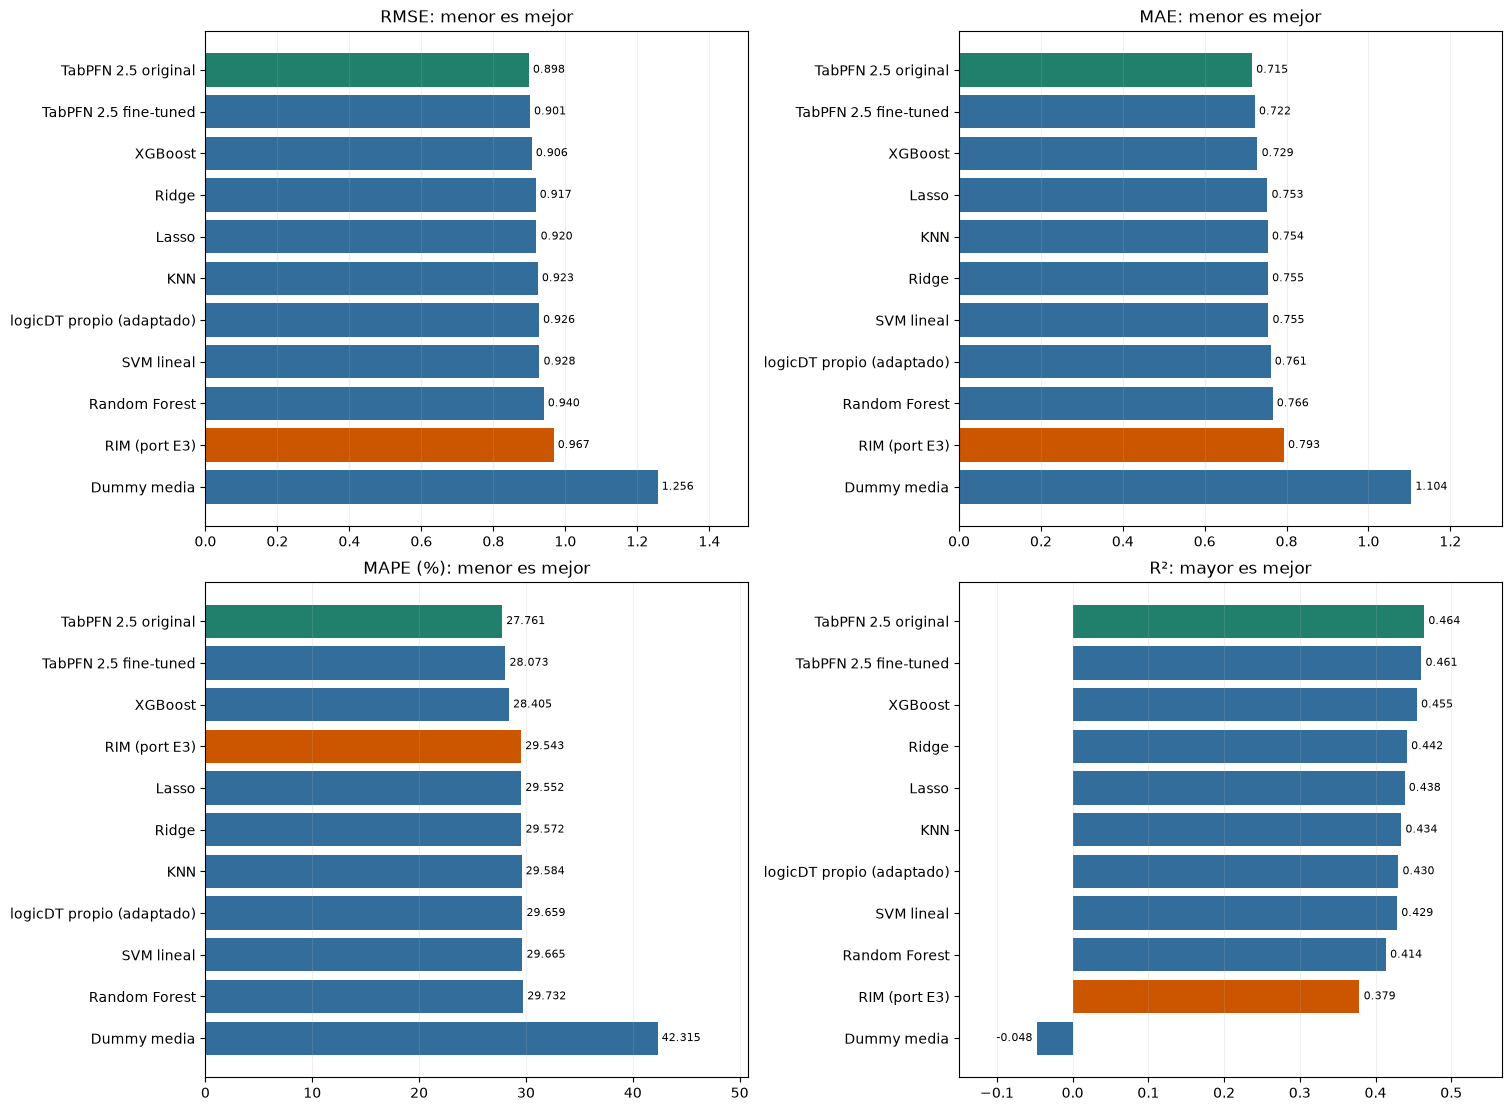

,modelo,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_nueve_metodos
0,KNN,RMSE,-0.004436,-0.044821,0.036077,0.82690,1.00000
1,Ridge,RMSE,-0.010615,-0.032070,0.005268,0.31128,1.00000
2,Lasso,RMSE,-0.008056,-0.020001,0.001928,0.15770,1.00000
3,Random Forest,RMSE,0.011930,-0.024657,0.048603,0.51846,1.00000
4,XGBoost,RMSE,-0.021432,-0.054703,0.012122,0.21102,1.00000
5,logicDT,RMSE,-0.001268,-0.036852,0.030833,0.94434,1.00000
6,TabPFN original,RMSE,-0.029428,-0.061618,0.002094,0.06888,0.61992
7,TabPFN ajustado,RMSE,-0.026336,-0.056160,0.002756,0.08018,0.64144
8,RIM,RMSE,0.039507,-0.013963,0.095171,0.16266,1.00000


In [3]:
from evaluar_tabpfn25_finetuned_e3 import show
cv_paths = ['clasicos/fold_metrics.csv', 'logicdt/fold_metrics.csv',
            'tabpfn_25/fold_metrics.csv', 'rim/fold_metrics.csv']
external = pd.concat([pd.read_csv(BOOK / 'resultados/e3' / path) for path in cv_paths], ignore_index=True)
cv_table = external.groupby('Modelo')[['RMSE', 'MAE', 'MAPE (%)', 'R²']].mean().add_suffix(' media CV')
cv_table['RMSE SD CV (ddof0)'] = external.groupby('Modelo').RMSE.std(ddof=0)
display(cv_table.sort_values('RMSE media CV').round(6))
cv_table.to_csv(BOOK / 'resultados/e3/rim/comparacion_cv_externa.csv')
show(report)
display(pd.DataFrame(report['family_vs_svm']).round(6))

## Significancia y búsqueda de varios métodos

Contrastes bilaterales de permutación pareada por estudiante99999; IC95% percentiles con
10000 réplicas bootstrap pareadas, semilla42. La diferencia es RIM menos referencia:
negativa favorece a RIM para RMSE, positiva para R². Un p pequeño también puede indicar
que RIM es **peor**: hay que comprobar la dirección de la diferencia.

RMSE y R² dan el mismo contraste de SSE en este test y no son dos evidencias independientes.
Se muestra Holm sobre los dos pares actuales (RIM vs TabPFN original y vs SVM). Además se
recalcula una familia fija de nueve candidatos observados frente al SVM: KNN, Ridge, Lasso,
RF, XGBoost, logicDT, TabPFN original, TabPFN ajustado y RIM, con Holm para esos nueve pares.
Los IC son marginales, sin ajuste simultáneo.

**Límite:** el test ya se ha consultado para múltiples métodos. La corrección de la familia
conocida no convierte una búsqueda adaptativa indefinida en un experimento confirmatorio.
Se reporta el resultado completo, favorable o desfavorable. Una mejora definitiva requerirá
datos nuevos reservados y un criterio de selección fijado antes de examinarlos. No se buscan
semillas ni grillas mirando test hasta obtener p<.05; no rechazar H0 tampoco prueba equivalencia.

In [4]:
for comp in report['paired_comparisons']:
    row = comp['rows'][0]
    significant_improvement = (row['diferencia_ajustado_menos_referencia'] < 0
                               and row['p_Holm_dos_pares'] < .05)
    print(comp['referencia'], ': mejora significativa de RMSE (dos pares, Holm):', significant_improvement)
    print('  deltaRMSE=', row['diferencia_ajustado_menos_referencia'],
          'p bilateral=', row['p_bilateral'], 'p Holm=', row['p_Holm_dos_pares'])
print('Resultados:', report['outputs'])
print('Modelo local con memoria de entrenamiento:', report['private_model'])

TabPFN 2.5 original : mejora significativa de RMSE (dos pares, Holm): False
  deltaRMSE= 0.0689356610385855 p bilateral= 0.00882 p Holm= 0.01764
SVM lineal : mejora significativa de RMSE (dos pares, Holm): False
  deltaRMSE= 0.039507364044466864 p bilateral= 0.16266 p Holm= 0.16266
Resultados: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\resultados\e3\rim
Modelo local con memoria de entrenamiento: C:\Users\Rubiel\Documents\Machine Learning Maestria\Precalculo\modelos_preentrenados\rim_e3\modelo_final.joblib


## Artefactos y reproducibilidad

`resultados/e3/rim/` contiene protocolo previo a test, grillas internas, auditoría, métricas
por fold, predicciones OOF/test sin IDs, comparaciones y procedencia con hashes/versiones.
El estimador serializado incluye la memoria de entrenamiento con etiquetas e identificadores
para excluir estudiantes: se guarda únicamente en `modelos_preentrenados/rim_e3/`, ignorado
en Git. No se publica el modelo ni se cambia automáticamente el modelo activo del dashboard.